## Data Science with Penguins

In [2]:
#pip install --upgrade seaborn pandas
#pip install seaborn
#pip install pandas

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import numpy as np#why is this not enough?
#1. Dataframes !!! (tabular, )
#2. group_by !!
# module polars ?
# in general there is a constant tension between speed and comfort

import pandas as pd
import seaborn

# Palmer Penguins

* [Look at the data](#Look-at-the-data)
* [Simple Summary Stats](#Simple-Summary-Stats)
* [The powerful pandas](#The-powerful-pandas)
* [Simpson's Paradox](#Simpson's-Paradox)

## Look at the data

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

penguins = sns.load_dataset("penguins")
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [4]:
#ämap:

pDict = {"Adelie": 1,
         "Chintoo": 2}



# Simple Summary Stats

* How many on each island ?
* What are the mean weight and flipper length ?
* What do the distributions of weight and flipper length look like?
* Are there differences in the body mass of penguins by sex within each species?

-------------------

- Repeat all of the above grouping by species.
- Try numerical and graphical summaries

In [5]:
# @title How many on each island ?
penguins.groupby("island").species.count()

#np.unique(penguins.island, return_counts = True)

island
Biscoe       168
Dream        124
Torgersen     52
Name: species, dtype: int64

In [6]:
# @title What are the mean weight and flipper length ?
#np.mean(penguins[["flipper_length_mm",	"body_mass_g"]])

#left to right operations !!
penguins[["flipper_length_mm",	"body_mass_g"]].mean()
#Repeat the above grouping by species.

penguins.groupby("species")[["flipper_length_mm",	"body_mass_g"]].mean()


,flipper_length_mm,body_mass_g
species,,
Adelie,189.953642,3700.662252
Chinstrap,195.823529,3733.088235
Gentoo,217.186992,5076.016260


In [7]:
penguins.groupby("species")["body_mass_g"].mean()
#is there another way than the quote to access single columns?:
penguins.groupby("species").body_mass_g.mean()
#this can be dangerous in certain situations
penguins["body_mass_g"]
#note2self: could this work for multiple columns ??


0      3750.0
1      3800.0
2      3250.0
3         NaN
4      3450.0
        ...  
339       NaN
340    4850.0
341    5750.0
342    5200.0
343    5400.0
Name: body_mass_g, Length: 344, dtype: float64

In [8]:
# @title mean flipper length


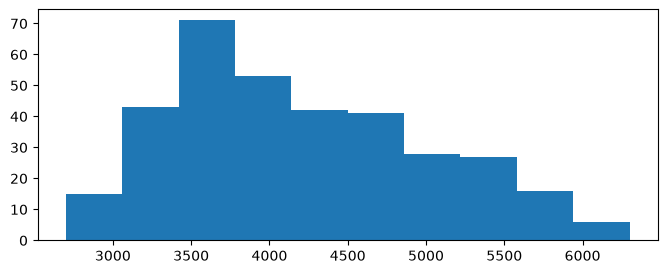

In [9]:
#histogram of weight:
plt.figure(figsize=(8,3));
plt.hist(penguins.body_mass_g, bins = 10);


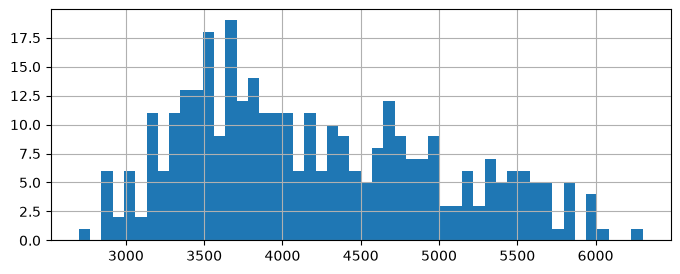

In [10]:
plt.figure(figsize=(8,3));
penguins.body_mass_g.hist(bins=50);

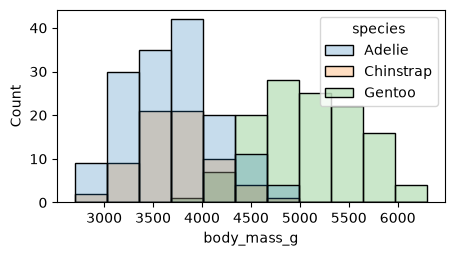

In [11]:
# Histogram for weight (body mass)
plt.figure(figsize=(5, 2.5))
sns.histplot(data = penguins, x ="body_mass_g",hue = "species", alpha = 0.25);

## Grouping

The `seaborn` library offers simple grouping in their plots via the `hue` argument:

## Box plots

Side-by-side comparisons are much easier with box plots:

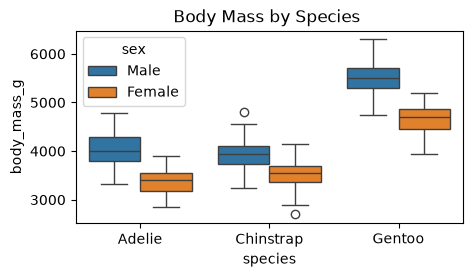

In [12]:
# Box plot of body mass by species and sex
plt.figure(figsize=(5, 2.5))
sns.boxplot(data = penguins, y ="body_mass_g", x="species", hue = "sex")
plt.title('Body Mass by Species ');
plt.show();

## Scatter Plots

array([[nan, nan],
       [nan, nan]])

<Figure size 400x200 with 0 Axes>

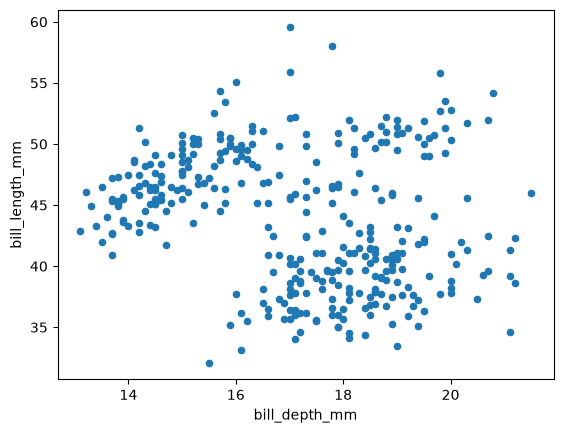

<Figure size 400x200 with 0 Axes>

In [13]:
# @title bill_length_mm vs bill_depth_mm
plt.figure(figsize=(4, 2));
from matplotlib import pyplot as plt
penguins.plot(x = "bill_depth_mm", y = "bill_length_mm", kind = "scatter");
plt.figure(figsize=(4, 2));
# there are clearly MANY scatter plots that we can look at !
# It would require a lot of code to create that many
# 4*3/2
#correlation coefficient quantifies the linear dependence
# it is in the range [-1,1]
np.corrcoef(penguins.bill_depth_mm, penguins.bill_length_mm)
#What is nan ?


# The powerful pandas

When we want to **group** numerical summaries by categorical variables, the `pandas` library is VERY useful.

So let us repeat the previous inquiries.

**Simple Summary Stats**

* How many on each island **per species**?
* What are the mean weight and flipper length **per species and sex**?
* Are there differences in the body mass of penguins **by sex within each species**?



In [14]:
#left to right sequential command logic:
penguins.flipper_length_mm.mean().round(2)

np.float64(200.92)

# Simpson's Paradox

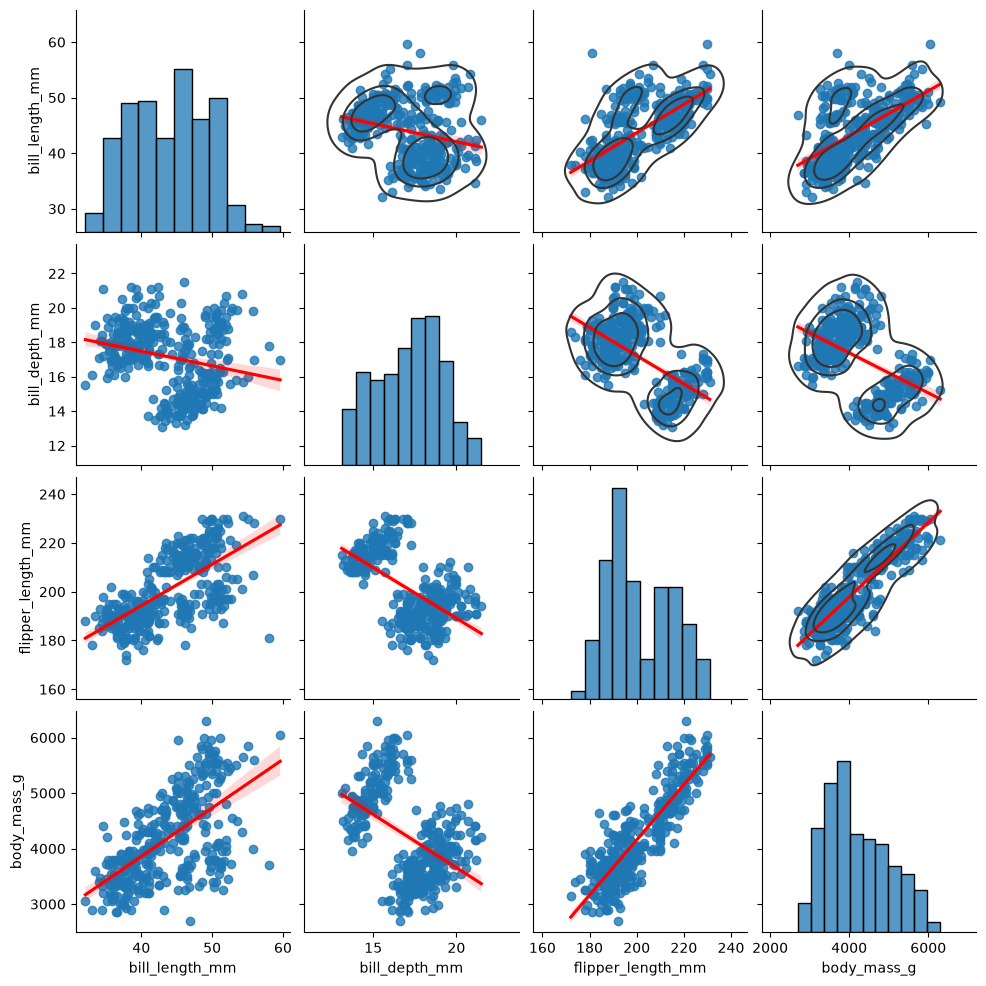

In [15]:
# @title pairwise scatter plots

g=sns.pairplot(penguins, kind="reg", plot_kws={'line_kws':{'color':'red'}}, corner=False);#
g.map_upper(sns.kdeplot, levels=4, color=".2");
plt.show()

The "data tells us" that
* bill depth seems to **decrease** with bill length
* flipper length and body mass seem to **decrease** with bill depth.
* flipper length and body mass seem to **increase** with bill length.

Can we fit simple regression lines to prove our visual hypothesis?

In [26]:
# @title Simple Regression: bill_depth_mm versus bill_length_mm

import statsmodels.api as sm
import statsmodels.formula.api as smf

lm1 = smf.ols('bill_depth_mm ~ bill_length_mm*species', penguins).fit()
lm1.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,11.4091,1.138,10.025,0.000,9.170,13.648
species[T.Chinstrap],-3.8400,2.054,-1.870,0.062,-7.880,0.200
species[T.Gentoo],-6.1581,1.755,-3.510,0.001,-9.609,-2.707
bill_length_mm,0.1788,0.029,6.110,0.000,0.121,0.236
bill_length_mm:species[T.Chinstrap],0.0434,0.046,0.952,0.342,-0.046,0.133
bill_length_mm:species[T.Gentoo],0.0260,0.041,0.642,0.522,-0.054,0.106


DataCamp uses the simpler `np.polyfit()`.
But:

1. no missing values allowed
2. no statistical inference provided

In [17]:
# DataCamp uses the simpler `np.polyfit()`:
# Drop rows with NaN in the relevant columns before fitting
penguins_cleaned = penguins.dropna(subset=['bill_length_mm', 'bill_depth_mm'])
np.polyfit(penguins_cleaned.bill_length_mm, penguins_cleaned.bill_depth_mm, 1)

array([-0.08502128, 20.88546832])

In [18]:
# @title Simple Regression: flipper_length_mm vs. bill_depth_mm

lm2 = smf.ols('flipper_length_mm ~ bill_depth_mm', penguins).fit()
lm2.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,272.2190,5.413,50.294,0.000,261.573,282.865
bill_depth_mm,-4.1574,0.314,-13.261,0.000,-4.774,-3.541


BUT: the interpretation of the data is model dependent !
The data does not "tell the truth" by itself:

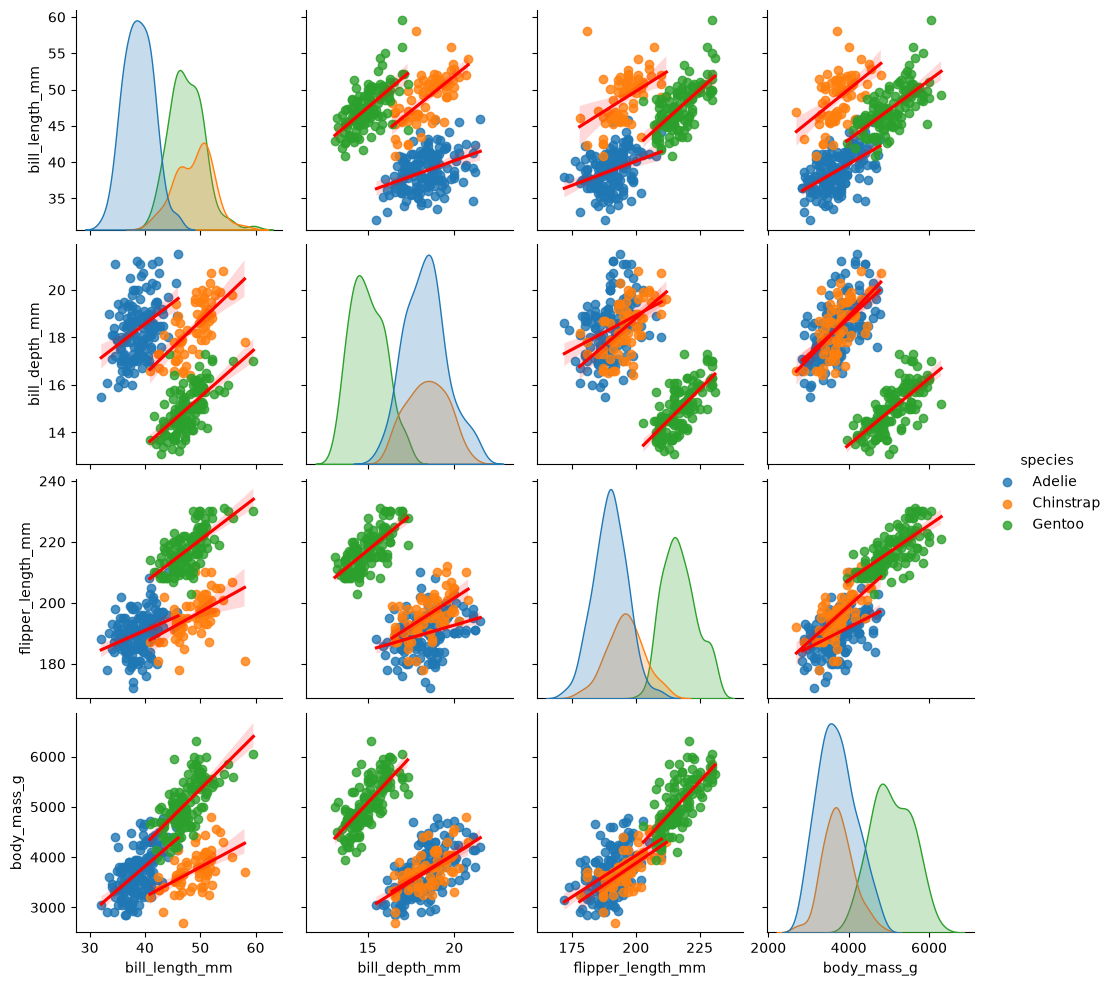

In [19]:
# @title Slope Reversal

sns.pairplot(penguins,  hue="species", kind="reg", plot_kws={'line_kws':{'color':'red'}}, corner=False);
plt.show()

In [20]:
# @title Interaction Terms in Regression

lm2a = smf.ols('flipper_length_mm ~ bill_depth_mm*species -1', penguins).fit()
lm2a.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
species[Adelie],159.6189,6.943,22.990,0.000,145.962,173.276
species[Chinstrap],128.6967,11.173,11.518,0.000,106.718,150.675
species[Gentoo],147.2243,7.795,18.887,0.000,131.892,162.557
bill_depth_mm,1.6534,0.378,4.379,0.000,0.911,2.396
bill_depth_mm:species[T.Chinstrap],1.9907,0.714,2.790,0.006,0.587,3.394
bill_depth_mm:species[T.Gentoo],3.0163,0.642,4.698,0.000,1.754,4.279


## Categorical Variables

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

penguins = sns.load_dataset("penguins")


lm2a = smf.ols('flipper_length_mm ~ species -1', penguins).fit()
lm2a.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
species[Adelie],189.9536,0.540,351.454,0.000,188.891,191.017
species[Chinstrap],195.8235,0.805,243.137,0.000,194.239,197.408
species[Gentoo],217.1870,0.599,362.676,0.000,216.009,218.365


Quizzes


In [22]:
import numpy as np
from numpy.random import default_rng

rng = default_rng(70)
#Generate 500 random integers between 80 and 90 (both boundaries are inclusive!)
x = rng.integers(80,90, 500)
x
np.mean(x)
x.mean()
#every "fourth value"
#print(x[0:10])
#print(x[:10:4])
np.sum(x[::4])
x > 85
np.sum(x > 85)
np.sum(x == 81)
x = np.arange(1,13)
x
x.reshape(4,3)

array([[ 1,  2,  3],
       [ 4,  5,  6],
       [ 7,  8,  9],
       [10, 11, 12]])

In [23]:
import numpy as np

url = "https://raw.githubusercontent.com/markusloecher/DataScience2018/master/data/diabetes.csv"
diabetes = np.loadtxt(url, delimiter=",", skiprows=1)
endRow=444
diabetes = diabetes[0:endRow,:]


In [24]:
np.mean(diabetes[:,0])
max(diabetes[:,1] ) - min(diabetes[:,1] )
diabetes[-1,0]
np.sum(diabetes[:,6]>0.3825)
np.unique(diabetes[:,0], return_counts=True)


(array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
        13., 14., 15., 17.]),
 array([62, 77, 57, 42, 42, 45, 22, 31, 21, 15, 11,  4,  6,  6,  1,  1,  1]))